In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

import os
import os.path as op
import glob
import sys
from datetime import date
import json
import natsort
from natsort import natsorted

import neuraltoolkit as ntk
#from samb_work import dimtools as dimt

# from ripple_detection import Karlsson_ripple_detector, Kay_ripple_detector
# from ripple_detection.simulate import simulate_time

from scipy.stats import ranksums

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})
plt.rcParams['font.serif'] = ['Arial']

today = date.today()
today = today.strftime("%Y_%m_%d")

if sys.platform == 'darwin':
    basedir = 'Volumes'
else:
    basedir = 'media'
    
pth = f'/{basedir}/HlabShare/appps1_cortical_communication_samb/review/swr'

#                        Colors
with open(f'/{basedir}/HlabShare/appps1_cortical_communication_samb/geno_colors.json') as json_file:
    geno_clrs = json.load(json_file)

dump = 1



In [2]:


def plot_state_boxplot_all_regions(data, ax=None):
    """
    Build the state x group boxenplot + per-animal stripplot overlay,
    pooled across all regions (no region filter).
    """
    state_cols = {
        'balanced_acc': 'Balanced',
        'nrem_acc': 'NREM',
        'rem_acc': 'REM',
        'wake_acc': 'Wake'
    }

    long_df = data.melt(
        id_vars=['animal', 'geno', 'age_group'],
        value_vars=list(state_cols.keys()),
        var_name='state',
        value_name='acc'
    )
    long_df['state'] = long_df['state'].map(state_cols)
    long_df['group'] = long_df['age_group'] + '_' + long_df['geno']

    state_order = ['Balanced', 'NREM', 'REM', 'Wake']
    group_order = ['young_wt', 'young_app_ps1', 'old_wt', 'old_app_ps1']

    animal_means = (
        long_df.groupby(['state', 'group', 'animal'])['acc']
        .mean()
        .reset_index()
    )

    palette = {
        'young_wt': '#a6cee3',
        'young_app_ps1': '#1f78b4',
        'old_wt': '#fb9a99',
        'old_app_ps1': '#e31a1c'
    }

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 3))

    sns.boxenplot(
        data=long_df, x='state', y='acc', hue='group',
        order=state_order, hue_order=group_order,
        palette=palette, showfliers=False, ax=ax,
    )
    sns.stripplot(
        data=animal_means, x='state', y='acc', hue='group',
        order=state_order, hue_order=group_order,
        palette=palette, dodge=True, ax=ax,
        size=6, edgecolor='black', linewidth=0.5, jitter=False
    )

    # Remove legend entirely
    ax.legend_.remove()

    ax.set_xlabel('')
    ax.set_ylabel('Balanced Accuracy', fontsize=10)
    ax.set_title('Decoding Accuracy by State, Genotype, and Age', fontsize=10)

    # Set tick label font sizes (both x and y)
    ax.tick_params(axis='both', labelsize=10)

    sns.despine(ax=ax)
    return ax


def plot_state_boxplot(data, region=None, ax=None):
    if region is not None:
        data = data[data['region'] == region]
    state_cols = {
        'balanced_acc': 'Balanced',
        'nrem_acc': 'NREM',
        'rem_acc': 'REM',
        'wake_acc': 'Wake'
    }
    long_df = data.melt(
        id_vars=['animal', 'geno', 'age_group'],
        value_vars=list(state_cols.keys()),
        var_name='state',
        value_name='acc'
    )
    long_df['state'] = long_df['state'].map(state_cols)
    long_df['group'] = long_df['age_group'] + '_' + long_df['geno']
    state_order = ['Balanced', 'NREM', 'REM', 'Wake']
    group_order = ['young_wt', 'young_app_ps1', 'old_wt', 'old_app_ps1']
    animal_means = (
        long_df.groupby(['state', 'group', 'animal'])['acc']
        .mean()
        .reset_index()
    )
    palette = {
        'young_wt': '#a6cee3',
        'young_app_ps1': '#1f78b4',
        'old_wt': '#fb9a99',
        'old_app_ps1': '#e31a1c'
    }
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 3))

    sns.boxenplot(
        data=long_df, x='state', y='acc', hue='group',
        order=state_order, hue_order=group_order,
        palette=palette, showfliers=False, ax=ax,
    )
    sns.stripplot(
        data=animal_means, x='state', y='acc', hue='group',
        order=state_order, hue_order=group_order,
        palette=palette, dodge=True, ax=ax,
        size=6, edgecolor='black', linewidth=0.5, jitter=False
    )

    # Remove legend entirely
    ax.legend_.remove()

    ax.set_xlabel('')
    ax.set_ylabel('Balanced Accuracy', fontsize=10)
#     title = f'Decoding Accuracy by State, Genotype, and Age — {region}' if region else 'Decoding Accuracy by State, Genotype, and Age'
    title = f'{region}'

    ax.set_title(title, fontsize=10)

    # Set tick label font sizes (both x and y)
    ax.tick_params(axis='both', labelsize=10)

    sns.despine(ax=ax)
    return ax



In [28]:
df = pd.read_pickle('/media/HlabShare/Toby_work/sleep_indiv_neuron/accuracy_dataframes/down_sampling_fixed_isi_5_3_5')

def extract_recepoch(row):
    prefix = f"{row['animal']}_{row['age']}_"
    suffix = f"_{row['cell_no']}_{row['geno']}"
    s = row['cell']
    if s.startswith(prefix) and s.endswith(suffix):
        return s[len(prefix):-len(suffix)]
    return None

df['recepoch'] = df.apply(extract_recepoch, axis=1)
print(df['recepoch'].isna().sum(), "rows failed to match")


0 rows failed to match


In [29]:
df['total_chunks'] = df['state_chunks_nrem']+df['state_chunks_rem']+df['state_chunks_wake']
#df['total_chunks'] = df['state_chunks_wake']+df['state_chunks_sleep']
df

,index,region,cell,animal,celltype,geno,cell_no,age,age_group,state_chunks_nrem,state_chunks_rem,state_chunks_wake,balanced_acc,nrem_acc,rem_acc,wake_acc,recepoch,total_chunks
0,0,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,5,3,5,0.670958,0.833333,0.222222,0.957317,1228_0_12,13
3,13,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,5,3,5,0.532407,0.000000,0.875000,0.722222,1228_0_12,13
6,26,ACad,caf69_358_1228_0_12_2_wt,caf69,RSU,wt,2,358,old,5,3,5,0.778632,0.769231,0.666667,0.900000,1228_0_12,13
9,39,ACad,caf69_358_1228_0_12_3_wt,caf69,RSU,wt,3,358,old,5,3,5,0.608588,0.538462,0.444444,0.842857,1228_0_12,13
12,52,ACad,caf69_358_1228_0_12_4_wt,caf69,RSU,wt,4,358,old,5,3,5,0.657051,0.846154,0.333333,0.791667,1228_0_12,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10128,43888,V1,bth100_99_0624_12_24_90_wt,bth100,RSU,wt,90,99,young,5,3,5,0.799325,0.750000,0.666667,0.981308,0624_12_24,13
10131,43901,V1,bth100_99_0624_12_24_91_wt,bth100,RSU,wt,91,99,young,5,3,5,0.422277,0.413793,0.833333,0.019704,0624_12_24,13
10134,43914,V1,bth100_99_0624_12_24_92_wt,bth100,RSU,wt,92,99,young,5,3,5,0.613889,0.812500,0.666667,0.362500,0624_12_24,13
10137,43927,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,5,3,5,0.510955,0.303030,0.666667,0.563169,0624_12_24,13


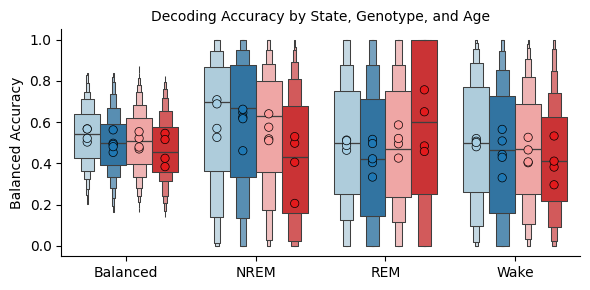

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
plot_state_boxplot_all_regions(df, ax=ax)
plt.tight_layout()
plt.show()

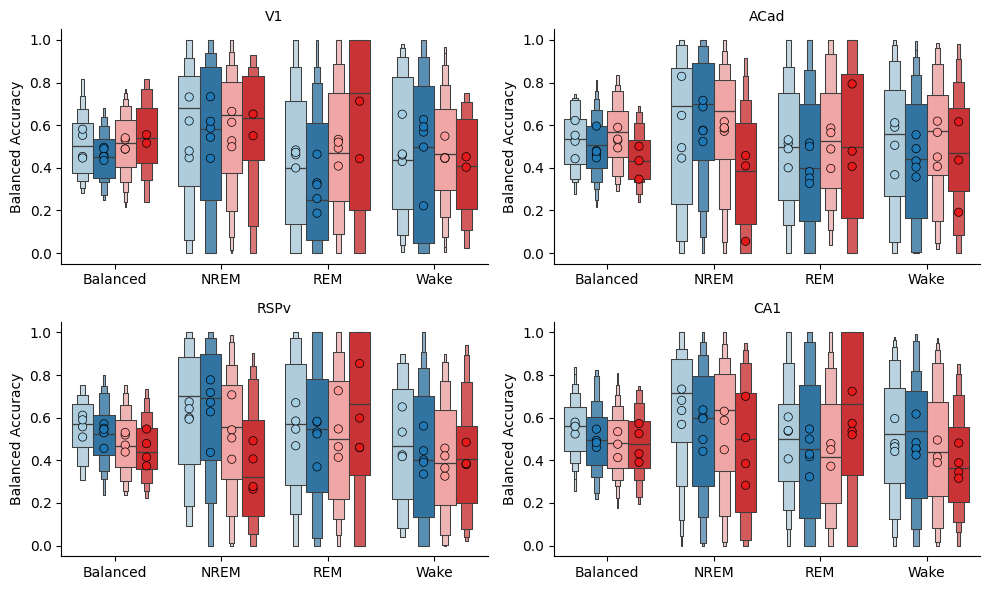

In [6]:
regions = ['V1', 'ACad', 'RSPv', 'CA1']

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for region, ax in zip(regions, axes.flat):
    plot_state_boxplot(df, region=region, ax=ax)

plt.tight_layout()
plt.show()


In [4]:
from rpy2.robjects.packages import importr
from rpy2.robjects.vectors import StrVector

%load_ext rpy2.ipython

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

pandas2ri.activate()  # enables automatic pandas <-> R dataframe conversion

# Enable cell magic for Rpy2 interface

In [30]:
%%R -i df
# df now exists as an R data.frame in this R session, named "df"
library(tidyverse)
library(lme4)
library(lmerTest)
library(emmeans)

classification_df <- df

#class_lmer = lmer(balanced_acc ~ geno * region * age_group + (1 | animal/recepoch) + state_chunks_nrem + state_chunks_rem + state_chunks_wake, data = classification_df)
class_lmer = lmer(balanced_acc ~ geno * region * age_group + (1 | animal/recepoch), data = classification_df)
#class_lmer = lmer(balanced_acc ~ geno * age_group + (1 | age), data = classification_df)
#Look into accounting for circadian effects

# # This will give us feedback about whether the main effects are significant 
# anova(class_lmer)

# emmeans(class_lmer, list(pairwise ~ geno | region | age_group ), adjust = 'tukey')

#emm <- emmeans(class_lmer, ~ geno | region | age_group, pbkrtest.limit=4318)
emm <- emmeans(class_lmer, ~ geno | region | age_group, lmer.df = "satterthwaite",  lmerTest.limit=4318)
#emm <- emmeans(class_lmer, ~ geno | age_group)
pairs(emm, adjust = 'tukey')



region = ACad, age_group = old:
 contrast     estimate     SE   df t.ratio p.value
 app_ps1 - wt  -0.0864 0.0342 16.0  -2.530  0.0223

region = CA1, age_group = old:
 contrast     estimate     SE   df t.ratio p.value
 app_ps1 - wt  -0.0223 0.0343 16.2  -0.650  0.5248

region = RSPv, age_group = old:
 contrast     estimate     SE   df t.ratio p.value
 app_ps1 - wt  -0.0607 0.0349 17.5  -1.736  0.1002

region = V1, age_group = old:
 contrast     estimate     SE   df t.ratio p.value
 app_ps1 - wt  -0.0289 0.0367 20.8  -0.788  0.4393

region = ACad, age_group = young:
 contrast     estimate     SE   df t.ratio p.value
 app_ps1 - wt  -0.0274 0.0339 17.8  -0.808  0.4299

region = CA1, age_group = young:
 contrast     estimate     SE   df t.ratio p.value
 app_ps1 - wt  -0.0606 0.0342 18.2  -1.774  0.0928

region = RSPv, age_group = young:
 contrast     estimate     SE   df t.ratio p.value
 app_ps1 - wt  -0.0138 0.0357 21.7  -0.387  0.7025

region = V1, age_group = young:
 contrast     estimat

In [31]:
%%R -i df
library(tidyverse)
library(lme4)
library(lmerTest)
library(emmeans)

classification_df <- df

# Map each outcome column to a readable state label
state_cols <- c(
  balanced_acc = "Balanced",
  nrem_acc     = "NREM",
  rem_acc      = "REM",
  #sleep_acc = "Sleep",
  wake_acc     = "Wake"
)

all_results <- list()

for (col in names(state_cols)) {
  # Build formula dynamically so we can swap the outcome each loop
  f <- as.formula(paste0(col, " ~ geno * region * age_group + (1 | animal/recepoch)"))
  #f <- as.formula(paste0(col, " ~ geno * region * age_group + (1 | animal/recepoch) + state_chunks_nrem + state_chunks_rem + state_chunks_wake"))
  m <- lmer(f, data = classification_df, )

  #emm <- emmeans(m, ~ geno | region * age_group, pbkrtest.limit = 4318)
  emm <- emmeans(m, ~ geno | region * age_group, lmer.df = "satterthwaite", lmerTest.limit=4318)
  contrast_df <- as.data.frame(pairs(emm, adjust = "none"))  # raw p-values only
  contrast_df$state <- state_cols[[col]]

  all_results[[col]] <- contrast_df
}

full_results <- bind_rows(all_results)

# Single BH correction across all 32 rows (4 states x 4 regions x 2 age_groups)
full_results$p_adj_BH <- p.adjust(full_results$p.value, method = "BH")

full_results %>% arrange(p_adj_BH)


R[write to console]: boundary (singular) fit: see help('isSingular')



region = ACad, age_group = old:
 contrast     estimate     SE   df t.ratio p.value state    p_adj_BH
 app_ps1 - wt  -0.2205 0.0723 14.9  -3.052  0.0081 NREM        0.128
 app_ps1 - wt  -0.0864 0.0342 16.0  -2.530  0.0223 Balanced    0.178
 app_ps1 - wt  -0.0875 0.0640 15.3  -1.367  0.1915 Wake        0.480
 app_ps1 - wt   0.0498 0.0618 42.2   0.806  0.4246 REM         0.605

region = CA1, age_group = old:
 contrast     estimate     SE   df t.ratio p.value state    p_adj_BH
 app_ps1 - wt   0.1630 0.0621 42.3   2.625  0.0120 REM         0.128
 app_ps1 - wt  -0.1331 0.0724 15.0  -1.839  0.0858 NREM        0.356
 app_ps1 - wt  -0.0844 0.0642 15.5  -1.314  0.2078 Wake        0.480
 app_ps1 - wt  -0.0223 0.0343 16.2  -0.650  0.5248 Balanced    0.605

region = RSPv, age_group = old:
 contrast     estimate     SE   df t.ratio p.value state    p_adj_BH
 app_ps1 - wt  -0.2214 0.0738 16.2  -3.001  0.0084 NREM        0.128
 app_ps1 - wt  -0.0607 0.0349 17.5  -1.736  0.1002 Balanced    0.356
 app_p